
# Customer Segmentation Using K-Means Clustering

## Project Overview
This project uses machine learning to segment retail customers
based on their purchasing behaviour.

## Objectives
1. Load and understand the retail dataset.
2. Clean and preprocess the data.
3. Extract customer-level purchasing features.
4. Apply feature scaling.
5. Find the optimal number of clusters using the Elbow Method.
6. Perform K-Means clustering.
7. Visualize customer segments using PCA.
8. Analyze and summarize customer segments.

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook

In [1]:

%pip install -q pandas numpy matplotlib seaborn scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.


In [2]:

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:

# Dataset file
DATA_FILE = "Online Retail.xlsx"

# Check whether the file exists
if not Path(DATA_FILE).exists():
    raise FileNotFoundError(
        f"{DATA_FILE} not found. "
        "Upload the Excel file into the same folder as this notebook."
    )

# Load Excel dataset
df = pd.read_excel(
    DATA_FILE,
    sheet_name=0,
    engine="openpyxl"
)

print("Dataset loaded successfully!")

print("\nDataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

Dataset loaded successfully!

Dataset shape: (541909, 8)

First five records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:

# Dataset information
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Statistical Summary:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303



Missing Values:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Duplicate Records:
5268


In [5]:

# Create a working copy
data = df.copy()

# Remove rows without customer IDs
data = data.dropna(subset=["CustomerID"])

# Convert customer IDs to strings
data["CustomerID"] = (
    data["CustomerID"].astype("int64").astype(str)
)

# Convert invoice dates into datetime format
data["InvoiceDate"] = pd.to_datetime(
    data["InvoiceDate"],
    errors="coerce"
)

# Convert quantity and price to numeric
data["Quantity"] = pd.to_numeric(
    data["Quantity"], errors="coerce"
)

data["UnitPrice"] = pd.to_numeric(
    data["UnitPrice"], errors="coerce"
)

# Remove invalid dates and numeric values
data = data.dropna(
    subset=["InvoiceDate", "Quantity", "UnitPrice"]
)

# Remove cancelled invoices
data = data[
    ~data["InvoiceNo"].astype(str).str.upper().str.startswith("C")
]

# Keep only positive quantities and prices
data = data[
    (data["Quantity"] > 0) &
    (data["UnitPrice"] > 0)
].copy()

# Calculate transaction revenue
data["TotalAmount"] = (
    data["Quantity"] * data["UnitPrice"]
)

print("Data cleaning completed!")

print("Cleaned dataset shape:", data.shape)

print("\nRemaining missing values:")
display(data.isnull().sum())

display(data.head())

Data cleaning completed!
Cleaned dataset shape: (397884, 9)

Remaining missing values:


InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
dtype: int64

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


Total Customers: 4338
Total Transactions: 18532
Total Revenue: £ 8911407.9


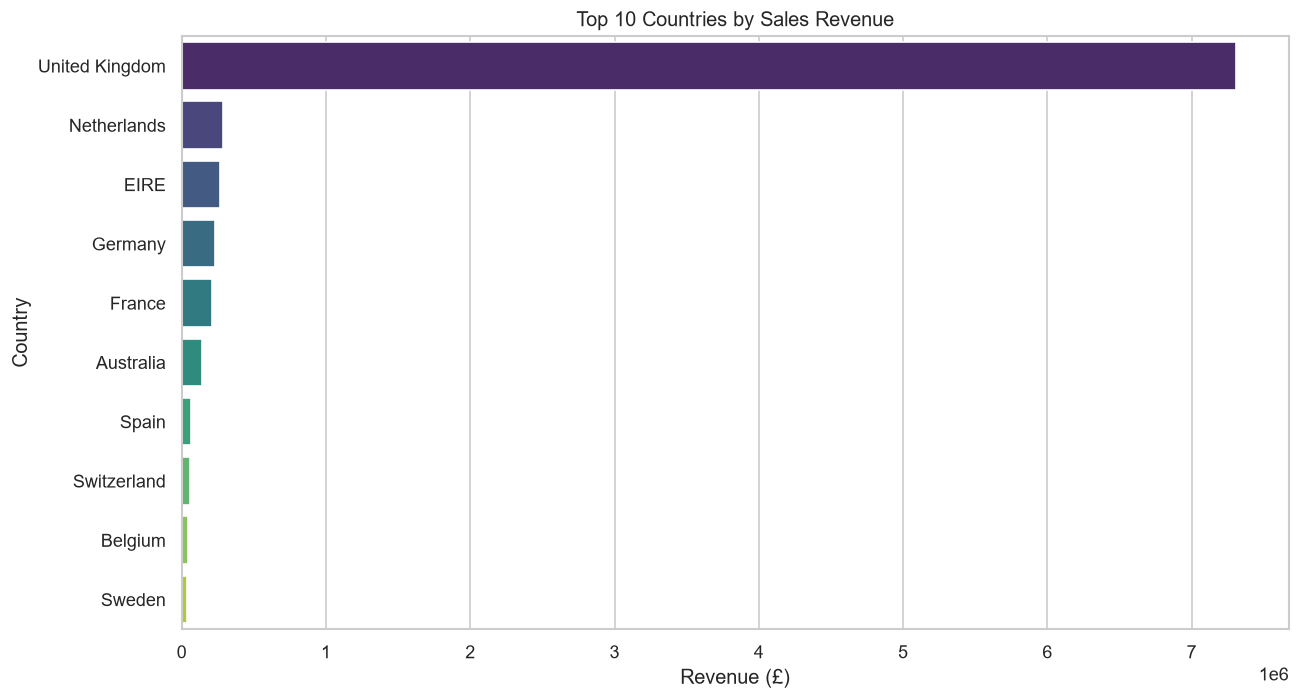

In [6]:

# Total customers
total_customers = data["CustomerID"].nunique()

# Total transactions
total_transactions = data["InvoiceNo"].nunique()

# Total revenue
total_revenue = data["TotalAmount"].sum()

print("Total Customers:", total_customers)
print("Total Transactions:", total_transactions)
print("Total Revenue: £", round(total_revenue, 2))

# Top 10 countries by revenue
country_sales = (
    data.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=country_sales.values,
    y=country_sales.index,
    hue=country_sales.index,
    palette="viridis",
    legend=False
)

plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [7]:

# Reference date: one day after the latest transaction
reference_date = data["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics for each customer
rfm = data.groupby("CustomerID").agg(
    Recency=("InvoiceDate",
             lambda x: (reference_date - x.max()).days),

    Frequency=("InvoiceNo", "nunique"),

    Monetary=("TotalAmount", "sum")
)

# Ensure valid positive RFM values
rfm = rfm[
    (rfm["Recency"] >= 0) &
    (rfm["Frequency"] > 0) &
    (rfm["Monetary"] > 0)
].copy()

print("Customer-level RFM data created!")

print("\nRFM dataset shape:", rfm.shape)

display(rfm.head(10))

print("\nRFM statistical summary:")
display(rfm.describe())

Customer-level RFM data created!

RFM dataset shape: (4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40
12352,36,8,2506.04
12353,204,1,89.00
12354,232,1,1079.40
12355,214,1,459.40



RFM statistical summary:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


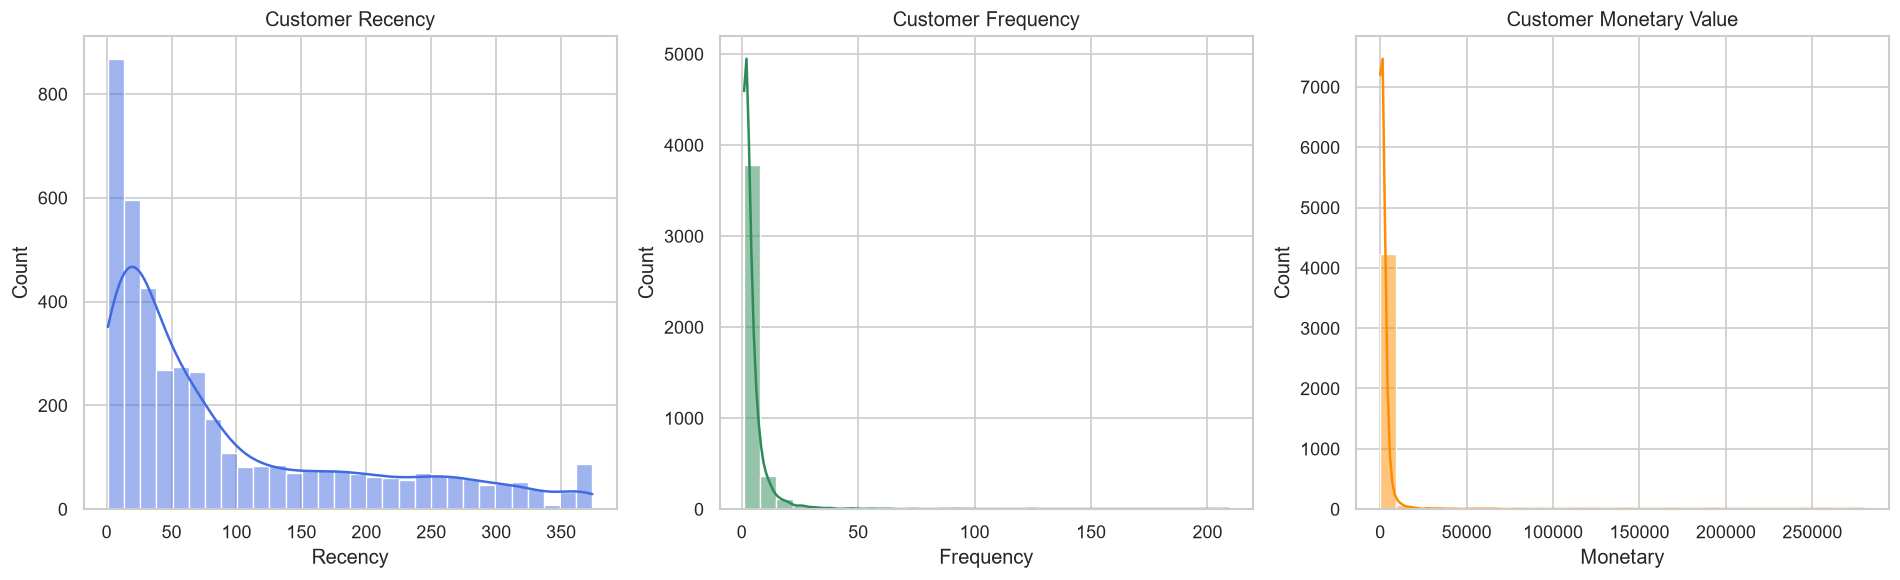

In [8]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(
    rfm["Recency"],
    bins=30,
    kde=True,
    ax=axes[0],
    color="royalblue"
)
axes[0].set_title("Customer Recency")

sns.histplot(
    rfm["Frequency"],
    bins=30,
    kde=True,
    ax=axes[1],
    color="seagreen"
)
axes[1].set_title("Customer Frequency")

sns.histplot(
    rfm["Monetary"],
    bins=30,
    kde=True,
    ax=axes[2],
    color="darkorange"
)
axes[2].set_title("Customer Monetary Value")

plt.tight_layout()
plt.show()

In [9]:

# Log transformation reduces positive skewness
rfm_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])

# Standardize features
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

print("Feature transformation completed!")
print("Feature scaling completed!")

display(rfm_scaled.head())

print("\nScaled feature means:")
print(rfm_scaled.mean().round(4))

print("\nScaled feature standard deviations:")
print(rfm_scaled.std().round(4))

Feature transformation completed!
Feature scaling completed!


,Recency,Frequency,Monetary
CustomerID,,,
12346,1.461993,-0.955214,3.706225
12347,-2.038734,1.074425,1.411843
12348,0.373104,0.386304,0.716489
12349,-0.623086,-0.955214,0.698739
12350,1.424558,-0.955214,-0.618962



Scaled feature means:
Recency     -0.0
Frequency   -0.0
Monetary     0.0
dtype: float64

Scaled feature standard deviations:
Recency      1.0001
Frequency    1.0001
Monetary     1.0001
dtype: float64


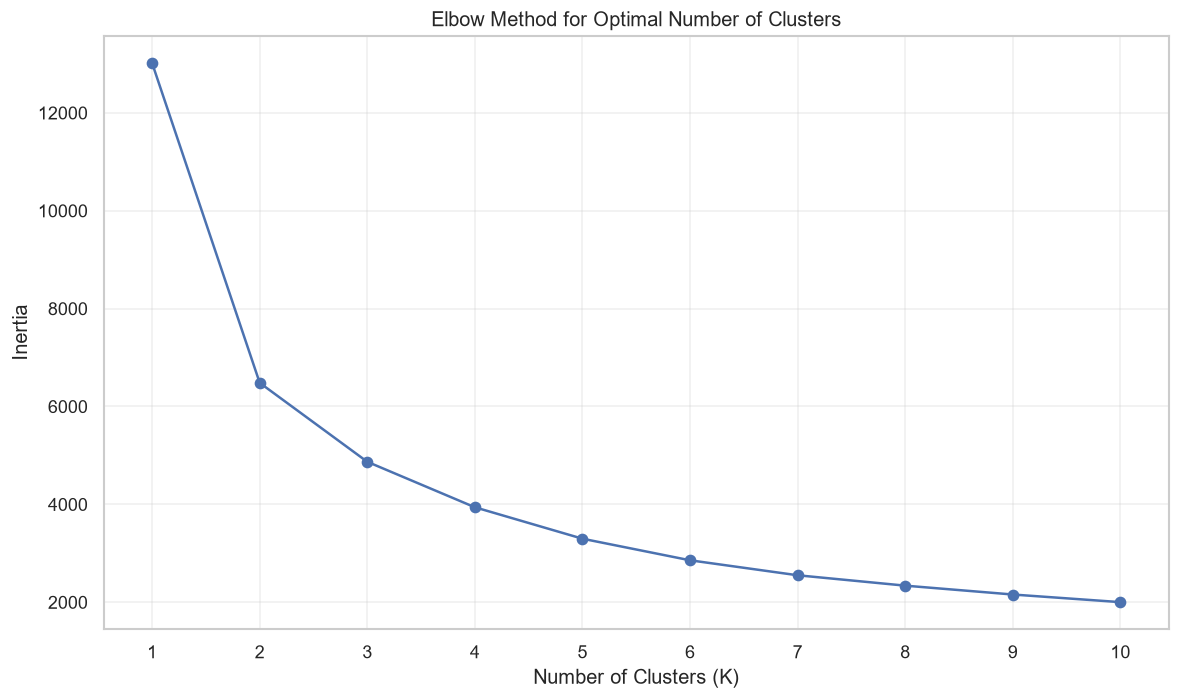

In [10]:
# ELBOW METHOD - FIND OPTIMAL NUMBER OF CLUSTERS

inertia_values = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(list(k_values), inertia_values, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("elbow_method.png", dpi=300)
plt.show()

In [11]:
# FINAL K-MEANS CLUSTERING

OPTIMAL_K = 3  # Change according to your Elbow plot

kmeans_final = KMeans(
    n_clusters=OPTIMAL_K,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans_final.fit_predict(rfm_scaled)

print("K-Means clustering completed successfully!")
print("Number of clusters:", OPTIMAL_K)

print("\nCluster counts:")
print(rfm["Cluster"].value_counts().sort_index())

K-Means clustering completed successfully!
Number of clusters: 3

Cluster counts:
Cluster
0     770
1    1872
2    1696
Name: count, dtype: int64


In [12]:
# SILHOUETTE SCORE - CLUSTER QUALITY EVALUATION

sil_score = silhouette_score(
    rfm_scaled,
    rfm["Cluster"]
)

print(f"Silhouette Score: {sil_score:.4f}")

if sil_score > 0.5:
    print("Cluster separation: Strong")
elif sil_score > 0.25:
    print("Cluster separation: Reasonable")
else:
    print("Cluster separation: Weak - clusters may overlap")

Silhouette Score: 0.3365
Cluster separation: Reasonable


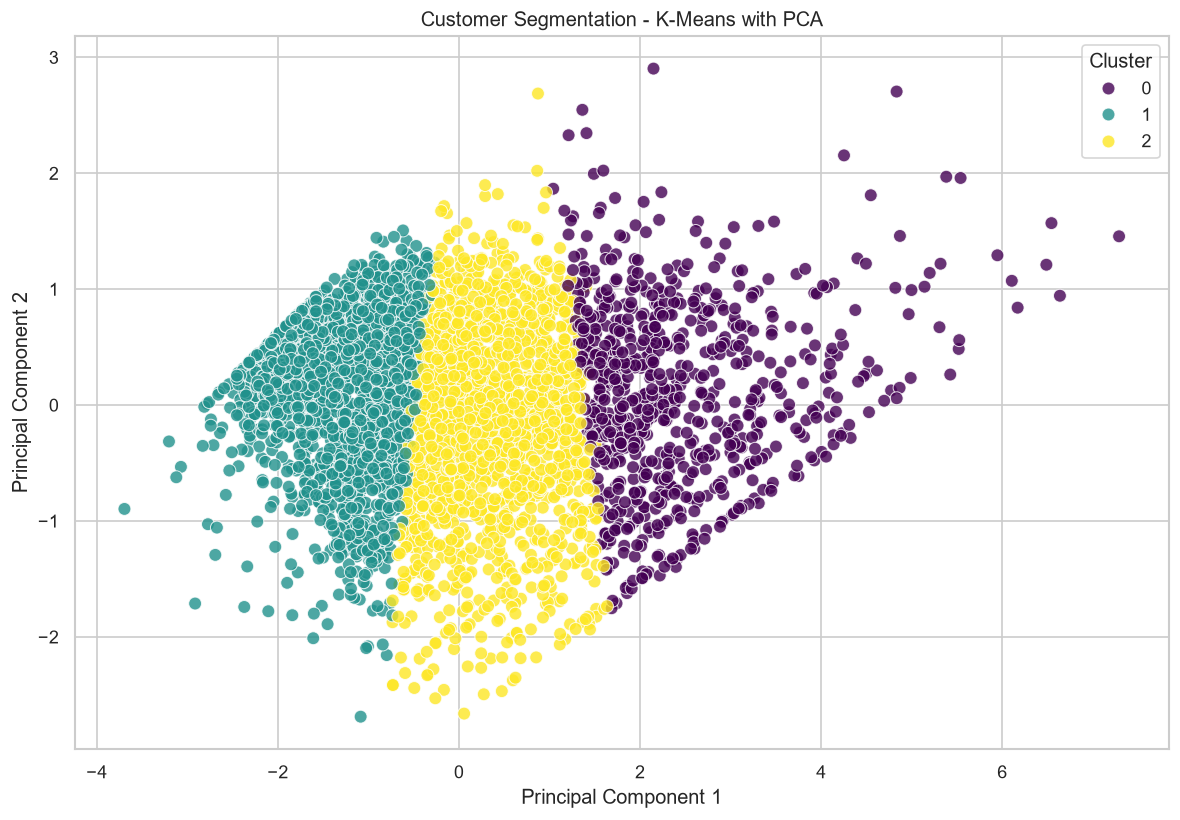

PCA explained variance:
[0.75102042 0.18759201]
Total variance explained by 2 components: 93.86 %


In [13]:
# PCA - VISUALIZE CUSTOMER SEGMENTS IN 2D

pca = PCA(n_components=2, random_state=42)

pca_components = pca.fit_transform(rfm_scaled)

pca_df = pd.DataFrame(
    pca_components,
    columns=["PC1", "PC2"],
    index=rfm.index
)

pca_df["Cluster"] = rfm["Cluster"].values

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="viridis",
    s=60,
    alpha=0.8
)

plt.title("Customer Segmentation - K-Means with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()

plt.savefig("customer_clusters_pca.png", dpi=300)
plt.show()

print("PCA explained variance:")
print(pca.explained_variance_ratio_)

print(
    "Total variance explained by 2 components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

CUSTOMER SEGMENT PROFILES


,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Percentage
Cluster,,,,,
0,770,17.06,13.34,7905.44,17.75
1,1872,167.36,1.35,362.54,43.15
2,1696,44.21,3.38,1265.06,39.10


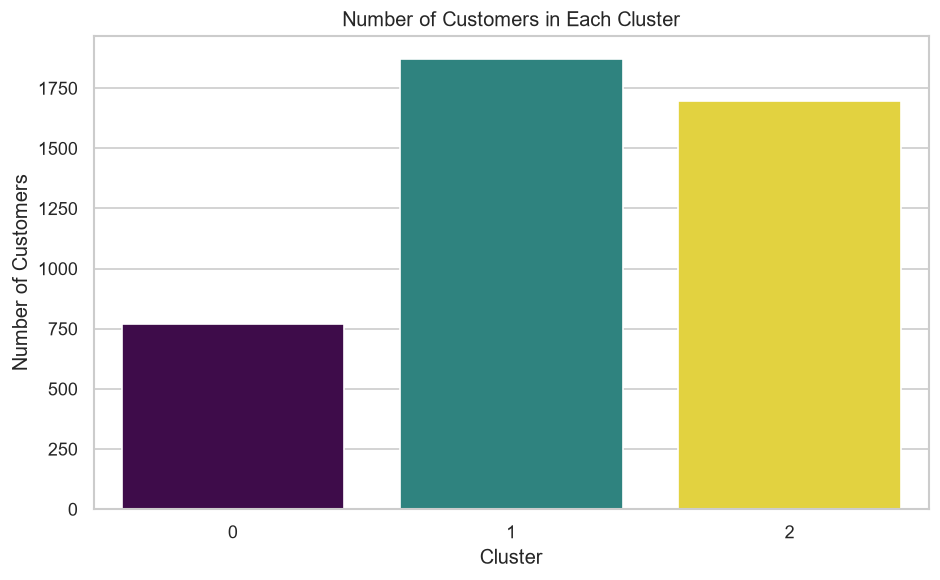

In [14]:
# CUSTOMER SEGMENT ANALYSIS

cluster_profile = rfm.groupby("Cluster").agg(
    Customer_Count=("Cluster", "size"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")
).round(2)

cluster_profile["Percentage"] = (
    cluster_profile["Customer_Count"]
    / cluster_profile["Customer_Count"].sum()
    * 100
).round(2)

print("CUSTOMER SEGMENT PROFILES")
display(cluster_profile)

# Visualize cluster sizes
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x="Cluster",
    hue="Cluster",
    palette="viridis",
    legend=False
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("cluster_sizes.png", dpi=300)
plt.show()

In [15]:
# SAVE FINAL PROJECT RESULTS

OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save customer segmentation results
rfm.to_csv(
    os.path.join(OUTPUT_DIR, "customer_segments.csv")
)

# Save cluster profiles
cluster_profile.to_csv(
    os.path.join(OUTPUT_DIR, "cluster_profiles.csv")
)

# Save PCA coordinates
pca_df.to_csv(
    os.path.join(OUTPUT_DIR, "pca_visualization_data.csv")
)

# Save inertia results
elbow_df = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values
})

elbow_df.to_csv(
    os.path.join(OUTPUT_DIR, "elbow_results.csv"),
    index=False
)

print("All project outputs saved successfully!")
print("Output folder:", OUTPUT_DIR)

All project outputs saved successfully!
Output folder: outputs


In [16]:
# VERIFY GENERATED OUTPUTS

print("\nPROJECT OUTPUT VERIFICATION")
print("-" * 40)

expected_files = [
    "elbow_method.png",
    "customer_clusters_pca.png",
    "cluster_sizes.png",
    os.path.join("outputs", "customer_segments.csv"),
    os.path.join("outputs", "cluster_profiles.csv"),
    os.path.join("outputs", "pca_visualization_data.csv"),
    os.path.join("outputs", "elbow_results.csv")
]

for file in expected_files:
    print(f"{'FOUND' if os.path.exists(file) else 'MISSING'}: {file}")


PROJECT OUTPUT VERIFICATION
----------------------------------------
FOUND: elbow_method.png
FOUND: customer_clusters_pca.png
FOUND: cluster_sizes.png
FOUND: outputs\customer_segments.csv
FOUND: outputs\cluster_profiles.csv
FOUND: outputs\pca_visualization_data.csv
FOUND: outputs\elbow_results.csv
